# Part 4: Salary Distribution and Compensation Analysis

In [1]:
# Import libraries :
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
# Load dataSet :
df = pd.read_csv(r"C:\Users\vssag\Desktop\Task 4.csv")

### Understanding the data set.

In [3]:
df.head() # It shows top five rows

,Employee ID,Department,Designation,Experience,Education Level,Salary,Performance Rating,Location
0,EMP00001,Human Resources,HR Executive,0.9,MBA,57500.0,4,Gurugram
1,EMP00002,Technology,IT Support Specialist,2.3,Diploma,79000.0,4,Delhi
2,EMP00003,Human Resources,HR Executive,0.1,Bachelor's,52000.0,4,Bengaluru
3,EMP00004,Administration,Operations Executive,2.9,Bachelor's,42500.0,1,Jaipur
4,EMP00005,Marketing,Marketing Executive,2.7,Master's,46000.0,3,Delhi


In [4]:
df.tail() # It shows last five rows

,Employee ID,Department,Designation,Experience,Education Level,Salary,Performance Rating,Location
2745,EMP02746,Operations,Operations Executive,4.3,Bachelor's,74000.0,3,Pune
2746,EMP02747,Finance,Finance & Accounting Specialist,1.7,Bachelor's,57500.0,3,Pune
2747,EMP02748,Technology,Engineering Manager,5.1,Diploma,132000.0,4,Noida
2748,EMP02749,Operations,Operations Executive,16.6,Bachelor's,76500.0,5,Noida
2749,EMP02750,Customer Support,IT Support Specialist,13.3,Master's,70500.0,2,Gurugram


In [5]:
df.shape # It will give dataset size(rows,column)

(2750, 8)

In [6]:
print(df.columns.tolist()) # It shows All column names in a list.

['Employee ID', 'Department', 'Designation', 'Experience', 'Education Level', 'Salary', 'Performance Rating', 'Location']


In [7]:
df.info() # It will give Dataset structure. 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2750 entries, 0 to 2749
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Employee ID         2750 non-null   object 
 1   Department          2750 non-null   object 
 2   Designation         2750 non-null   object 
 3   Experience          2717 non-null   float64
 4   Education Level     2750 non-null   object 
 5   Salary              2728 non-null   float64
 6   Performance Rating  2750 non-null   int64  
 7   Location            2750 non-null   object 
dtypes: float64(2), int64(1), object(5)
memory usage: 172.0+ KB


In [8]:
df.describe() # It shows statistical summary of the dataset

,Experience,Salary,Performance Rating
count,2717.000000,2728.000000,2750.000000
mean,6.172175,68401.451246,3.170909
std,5.113335,24072.822441,0.916220
min,0.000000,18000.000000,1.000000
25%,2.300000,51000.000000,3.000000
50%,4.800000,64500.000000,3.000000
75%,8.400000,82000.000000,4.000000
max,24.900000,209544.000000,5.000000


In [9]:
df.dtypes # it will shows Data types of columns.

Employee ID            object
Department             object
Designation            object
Experience            float64
Education Level        object
Salary                float64
Performance Rating      int64
Location               object
dtype: object

### Data Quality Checking

In [10]:
df.isnull().any() # Check any missing value in dataset by each column.

Employee ID           False
Department            False
Designation           False
Experience             True
Education Level       False
Salary                 True
Performance Rating    False
Location              False
dtype: bool

In [11]:
df.isnull().sum() # It shows all misiing not/nll in each column.

Employee ID            0
Department             0
Designation            0
Experience            33
Education Level        0
Salary                22
Performance Rating     0
Location               0
dtype: int64

In [12]:
df.nunique() # It will give The count of nunique values.

Employee ID           2750
Department              11
Designation             15
Experience             231
Education Level          6
Salary                 255
Performance Rating       5
Location                14
dtype: int64

### Data Consistency Checking

In [13]:
print(df["Department"].unique().tolist())# It shows unique value in department column.

['Human Resources', 'Technology', 'Administration', 'Marketing', 'Customer Support', 'Operations', 'Sales', 'Finance', 'technology', 'Cust. Support', 'HR']


In [14]:
df["Department"] = df["Department"].str.strip().str.title().replace({
    "Cust. Support": "Customer Support",
    "Hr": "Human Resources"
})

In [15]:
print(df["Department"].unique().tolist()) # Check again for confirmation.

['Human Resources', 'Technology', 'Administration', 'Marketing', 'Customer Support', 'Operations', 'Sales', 'Finance']


In [16]:
print(df["Designation"].unique().tolist()) # It shows unique value in Designation column.

['HR Executive', 'IT Support Specialist', 'Operations Executive', 'Marketing Executive', 'Software Engineer', 'Engineering Manager', 'Sales Executive', 'Data Analyst', 'Finance & Accounting Specialist', 'HR Manager', 'Sales Manager', 'Account Manager', 'QA Engineer', 'Business Development Executive', 'DevOps Engineer']


# Tasks: 

### 1. Clean salary and experience fields and handle missing records. 

In [17]:
# Clean Salary column.
df["Salary"].value_counts() # Check the frequency of each salary value

Salary
62000.0     43
55000.0     36
46500.0     35
53000.0     35
57000.0     32
            ..
146000.0     1
131000.0     1
82846.0      1
137000.0     1
132000.0     1
Name: count, Length: 255, dtype: int64

In [18]:
df["Salary"].max() # Find the highest salary.

209544.0

In [19]:
df["Salary"].min() # Find the minimum salary

18000.0

In [20]:
df["Salary"].sort_values() # Sort Salary values in ascending order to identify potential outliers

2556    18000.0
1528    18000.0
1366    18000.0
813     18000.0
2575    18000.0
         ...   
2435        NaN
2550        NaN
2637        NaN
2677        NaN
2693        NaN
Name: Salary, Length: 2750, dtype: float64

In [21]:
# Clean the Experience column.
df["Experience"].value_counts() # Check the frequency of Experience each Experience value

Experience
0.5     45
1.8     41
4.8     39
4.4     38
4.2     37
        ..
23.1     1
21.5     1
19.3     1
22.5     1
23.6     1
Name: count, Length: 231, dtype: int64

In [22]:
df["Experience"].min() # Find the lowest Experience

0.0

In [23]:
df["Experience"].max() #Find the highest Experience

24.9

In [24]:
df["Experience"].sort_values() # Sort Experience values in ascending order to identify potential outliers

428     0.0
1747    0.0
2643    0.0
2364    0.0
1366    0.0
       ... 
2489    NaN
2506    NaN
2550    NaN
2560    NaN
2668    NaN
Name: Experience, Length: 2750, dtype: float64

In [25]:
# Handle missing records.
df["Salary"].isna().sum() # count missing values in salary column

np.int64(22)

In [26]:
df["Salary"].describe() # It give stastical summary of salary column

count      2728.000000
mean      68401.451246
std       24072.822441
min       18000.000000
25%       51000.000000
50%       64500.000000
75%       82000.000000
max      209544.000000
Name: Salary, dtype: float64

In [27]:
df["Salary"].median() # It shows middle value of salary column.

64500.0

<Axes: >

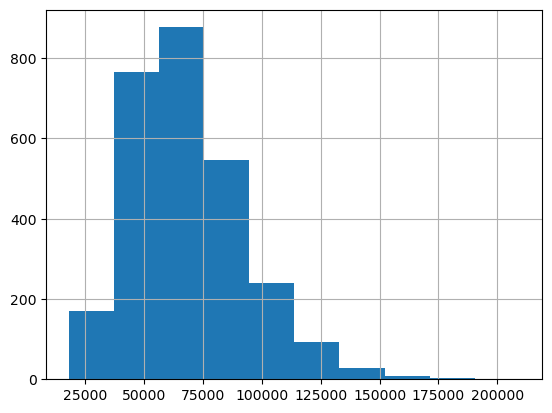

In [28]:
df["Salary"].hist() #  Check the distribution of Salary

In [29]:
df["Salary"] = df["Salary"].fillna(df["Salary"].median()) # Replcae missing value with middle value.

In [30]:
df["Salary"].isna().sum() # Check again for confirmation 

np.int64(0)

In [31]:
df["Experience"].isna().sum() # Check not/null value in Experience column

np.int64(33)

In [32]:
df["Experience"].describe() # provide Stastical summary of Experience.

count    2717.000000
mean        6.172175
std         5.113335
min         0.000000
25%         2.300000
50%         4.800000
75%         8.400000
max        24.900000
Name: Experience, dtype: float64

<Axes: >

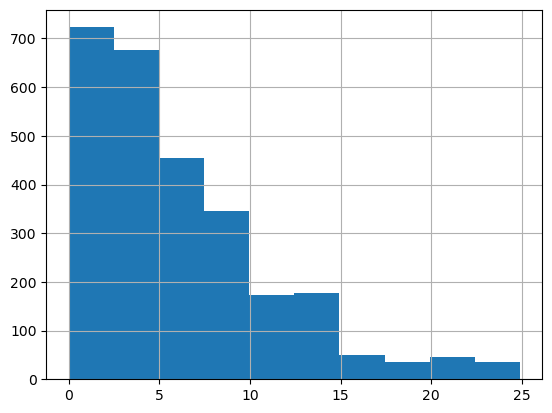

In [33]:
df["Experience"].hist() #  Check the distribution of Experience.

In [34]:
df["Experience"] = df["Experience"].fillna(df["Experience"].median()) # Replcae missing value with middle value.

In [35]:
df["Experience"].isna().sum() # Check again for confirmation.

np.int64(0)

### 2. Calculate mean, median, and standard deviation of salaries. ### 

In [36]:
df["Salary"].describe() # It will give statistical summary of salary column including mean median and standard deviation.

count      2750.000000
mean      68370.239636
std       23978.822489
min       18000.000000
25%       51000.000000
50%       64500.000000
75%       81875.000000
max      209544.000000
Name: Salary, dtype: float64

### 3. Calculate department-wise and designation-wise average salaries.

In [37]:
avg = df.groupby("Department")["Salary"].mean() # department wise salary average.
print(avg)

Department
Administration      46757.559585
Customer Support    49741.042345
Finance             73884.395833
Human Resources     63559.501718
Marketing           62268.518519
Operations          62332.475936
Sales               60818.783069
Technology          93735.875193
Name: Salary, dtype: float64


In [38]:
avg = df.groupby("Designation")["Salary"].mean() # Designatio wise salary average.
print(avg)

Designation
Account Manager                     63136.363636
Business Development Executive      50601.449275
Data Analyst                        91757.664634
DevOps Engineer                    104536.231884
Engineering Manager                127145.569620
Finance & Accounting Specialist     70672.110465
HR Executive                        59912.977143
HR Manager                          83585.491525
IT Support Specialist               55356.435208
Marketing Executive                 62268.518519
Operations Executive                57040.518453
QA Engineer                         81373.563218
Sales Executive                     53438.311688
Sales Manager                       82141.025641
Software Engineer                   95282.612245
Name: Salary, dtype: float64


### 3. Compare salary levels across experience groups and education levels.

In [39]:
print(df.columns.tolist()) # It shows All column names in a list.

['Employee ID', 'Department', 'Designation', 'Experience', 'Education Level', 'Salary', 'Performance Rating', 'Location']


In [40]:
experience= df.groupby("Experience")["Salary"].mean() # Calculate average salary by experience
print(experience)

Experience
0.0      54944.444444
0.1      53021.739130
0.2      56810.344828
0.3      62200.000000
0.4      62414.285714
            ...      
24.3     81500.000000
24.4     77666.666667
24.5     83500.000000
24.6    114166.666667
24.9     96750.000000
Name: Salary, Length: 231, dtype: float64


In [41]:
df["Experience Group"]="High Experience"
df.loc[df["Experience"].between(0,2),"Experience Group"] = "Low Experience"  # Create experience groups
df.loc[df["Experience"].between(2,10),"Experience Group"] = "Mid Experience"

In [42]:
df.groupby("Experience Group")["Salary"].mean()  # Calculate average salary for each experience group

Experience Group
High Experience    76881.139489
Low Experience     60842.135135
Mid Experience     68445.794421
Name: Salary, dtype: float64

In [43]:
experience= df.groupby("Education Level")["Salary"].mean() # Calculate average salary by education level
print(experience)

Education Level
Bachelor's     65677.423676
Diploma        66905.590106
High School    65412.623377
MBA            72594.660194
Master's       72338.915937
PhD            75347.826087
Name: Salary, dtype: float64


### 4. Identify unusually high or low salary observations using an appropriate statistical method. 


In [51]:
Q1 = df["Salary"].quantile(0.25)  # First quartile
Q3 = df["Salary"].quantile(0.75)  # Third quartile

IQR = Q3 - Q1  # Interquartile range

lower_limit = Q1 - 1.5 * IQR  # Lower limit
upper_limit = Q3 + 1.5 * IQR  # Upper limit

outliers = df[
    (df["Salary"] < lower_limit) |  # Below lower limit
    (df["Salary"] > upper_limit)    # Above upper limit
]

print(outliers["Salary"])  # Display outliers

65      130000.0
123     152000.0
196     141000.0
200     137000.0
230     139000.0
240     141000.0
401     174500.0
455     136000.0
512     143000.0
655     138500.0
671     130000.0
688     135000.0
699     144000.0
764     131000.0
766     130000.0
836     135000.0
887     130500.0
941     140500.0
995     140000.0
1218    133000.0
1274    131500.0
1281    154500.0
1316    128500.0
1337    141000.0
1469    133500.0
1477    209544.0
1508    146000.0
1570    157000.0
1577    131500.0
1612    155500.0
1613    151000.0
1628    149500.0
1681    130500.0
1774    139000.0
1797    143500.0
1865    142500.0
1950    130500.0
2036    140500.0
2066    129000.0
2164    154757.0
2222    135282.0
2223    157000.0
2282    129500.0
2315    128500.0
2344    140000.0
2391    141000.0
2392    130500.0
2393    156500.0
2397    172271.0
2450    183544.0
2456    130500.0
2475    128500.0
2515    141000.0
2526    128500.0
2532    153206.0
2661    136000.0
2713    130000.0
2722    140000.0
2747    132000

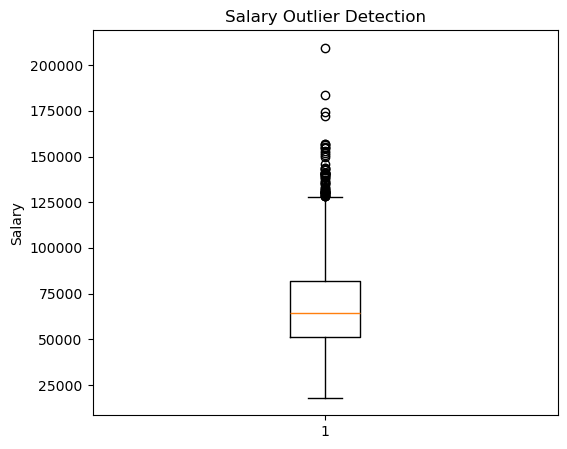

In [53]:
# Create a box plot to check salary outliers
plt.figure(figsize=(6,5))
salary = df["Salary"]
plt.boxplot(salary)
plt.title("Salary Outlier Detection")
plt.ylabel("Salary")
plt.show()

### 6. Create box plots comparing salary distributions across departments. 

C:\Users\vssag\AppData\Local\Temp\ipykernel_18664\2085031243.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = plt.boxplot(salary, patch_artist=True, labels=departments)


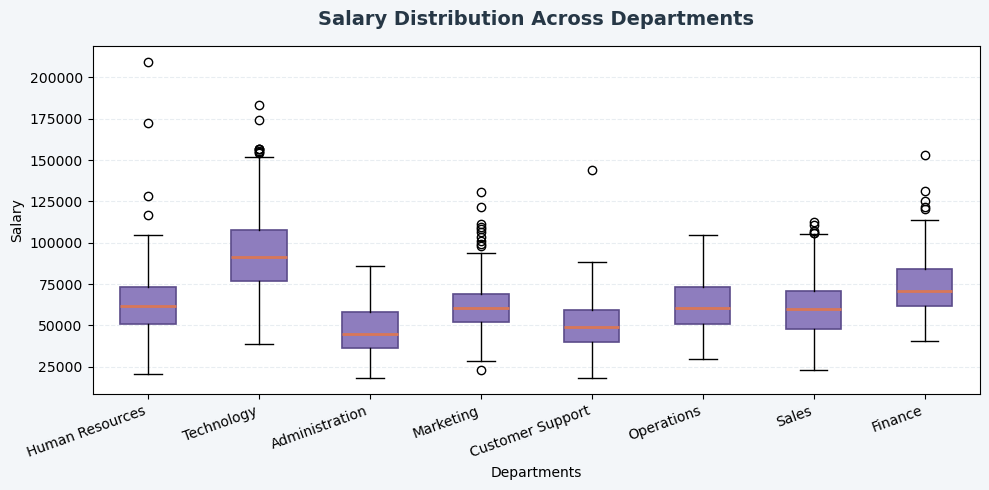

In [60]:
departments = df["Department"].unique()
salary = [df[df["Department"] == dept]["Salary"].dropna() for dept in departments]

plt.figure(figsize=(10, 5), facecolor="#F3F6F9")
ax = plt.gca()
ax.set_facecolor("#FFFFFF")

bp = plt.boxplot(salary, patch_artist=True, labels=departments)

for box in bp["boxes"]:
    box.set(facecolor="#8E7DBE", edgecolor="#5B4B8A", linewidth=1.2)

for median in bp["medians"]:
    median.set(color="#D97757", linewidth=2)

plt.title("Salary Distribution Across Departments",
          fontsize=14, fontweight="bold", color="#263746", pad=15)

plt.xlabel("Departments")
plt.ylabel("Salary")
plt.xticks(rotation=20, ha="right")

plt.grid(axis="y", linestyle="--", color="#D9E1E8", alpha=0.6)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### 8. Create a scatter plot showing experience against salary. 

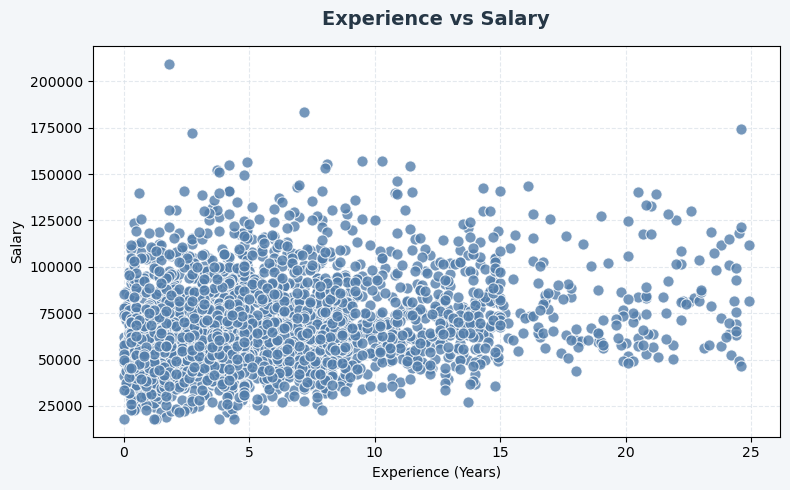

In [55]:
experience = df["Experience"]
salary = df["Salary"]

plt.figure(figsize=(8, 5), facecolor="#F3F6F9")
ax = plt.gca()
ax.set_facecolor("#FFFFFF")

plt.scatter(experience, salary, s=65, color="#527DAA",
            edgecolor="#FFFFFF", linewidth=0.8, alpha=0.8)

plt.title("Experience vs Salary",
          fontsize=14, fontweight="bold", color="#263746", pad=15)

plt.xlabel("Experience (Years)")
plt.ylabel("Salary")

plt.grid(linestyle="--", color="#D9E1E8", alpha=0.7)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### 8. Create a grouped bar chart comparing average salaries by designation and location.

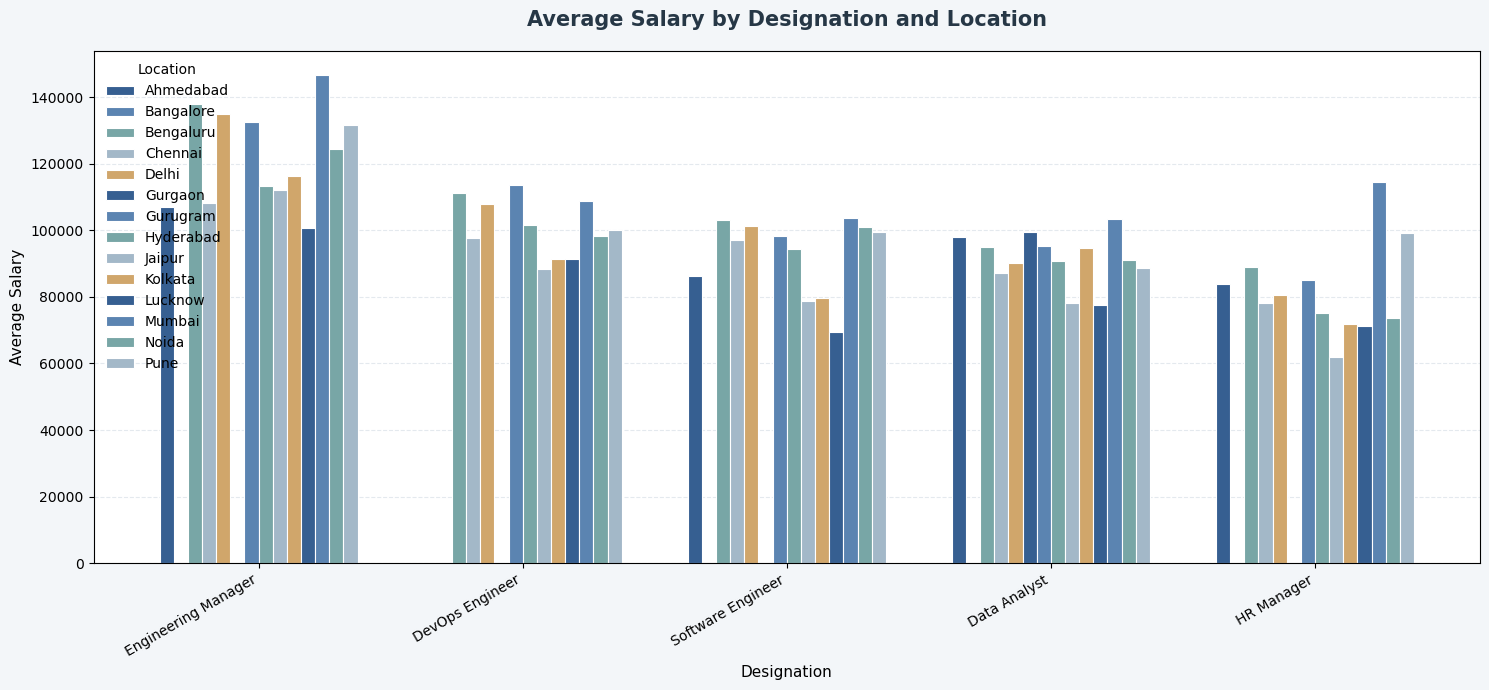

In [59]:
data = df.groupby(["Designation", "Location"])["Salary"].mean().unstack()

# Select the 5 designations with the highest average salaries
top5 = df.groupby("Designation")["Salary"].mean().nlargest(5).index

# Professional color palette
colors = ["#365F91", "#5B84B1", "#78A6A6", "#A3B8C8", "#D0A66B"]

ax = data.loc[top5].plot(
    kind="bar",
    figsize=(15, 7),
    width=0.75,
    color=colors[:len(data.columns)],
    edgecolor="white",
    linewidth=0.8)

ax.set_facecolor("#FFFFFF")
ax.figure.set_facecolor("#F3F6F9")

plt.title("Average Salary by Designation and Location",
          fontsize=15, fontweight="bold", color="#263746", pad=18)

plt.xlabel("Designation", fontsize=11)
plt.ylabel("Average Salary", fontsize=11)
plt.xticks(rotation=30, ha="right")

plt.grid(axis="y", linestyle="--", color="#D9E1E8", alpha=0.7)
ax.set_axisbelow(True)

plt.legend(title="Location", frameon=False)
plt.tight_layout()
plt.show()

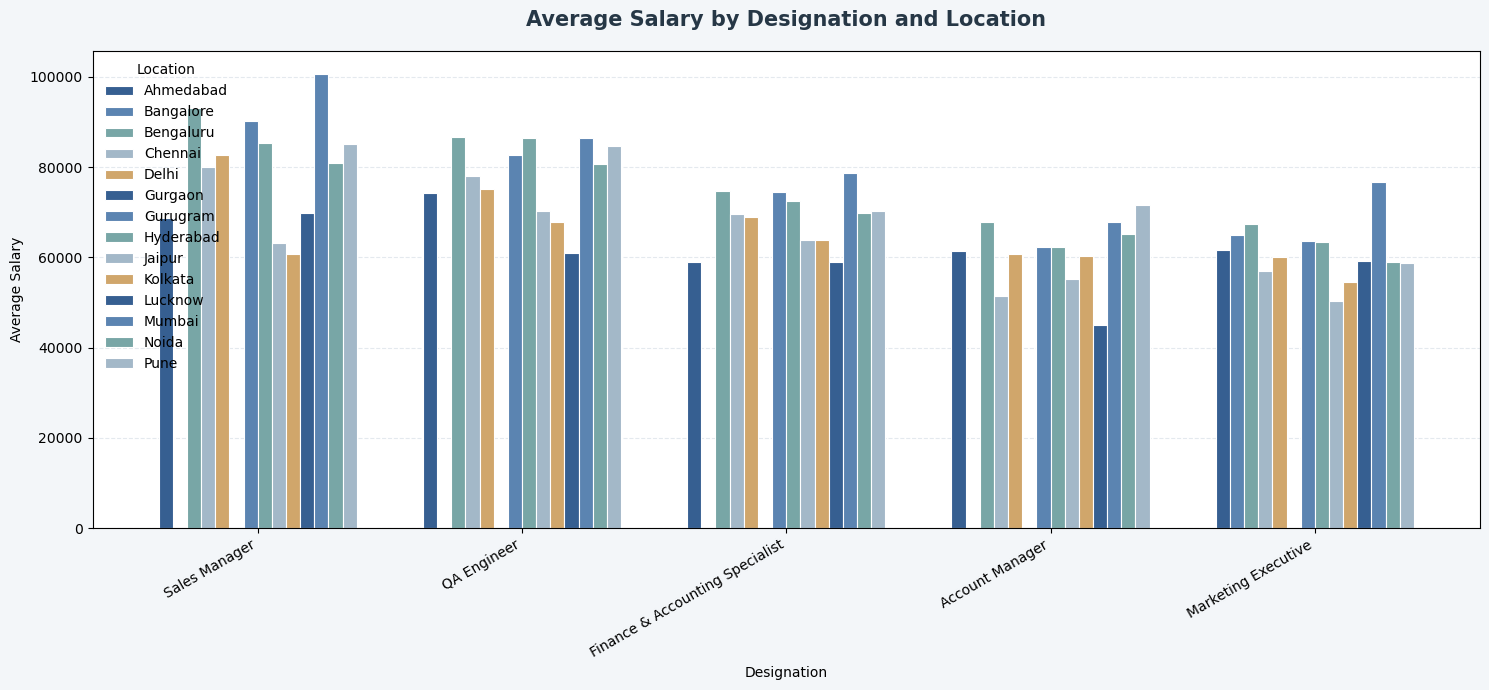

In [57]:
# Calculate average salary by designation and location
data = df.groupby(["Designation", "Location"])["Salary"].mean().unstack()

# Select the next 5 designations after the top 5
next5 = df.groupby("Designation")["Salary"].mean().nlargest(10).index[5:10]

# Professional color palette
colors = ["#365F91", "#5B84B1", "#78A6A6", "#A3B8C8", "#D0A66B"]

# Plot the grouped bar chart
ax = data.loc[next5].plot(
    kind="bar",
    figsize=(15, 7),
    width=0.75,
    color=colors[:len(data.columns)],
    edgecolor="white",
    linewidth=0.8
)

ax.set_facecolor("#FFFFFF")
ax.figure.set_facecolor("#F3F6F9")

plt.title("Average Salary by Designation and Location",
          fontsize=15, fontweight="bold", color="#263746", pad=18)

plt.xlabel("Designation")
plt.ylabel("Average Salary")
plt.xticks(rotation=30, ha="right")

plt.grid(axis="y", linestyle="--", color="#D9E1E8", alpha=0.7)
ax.set_axisbelow(True)

plt.legend(title="Location", frameon=False)
plt.tight_layout()
plt.show()

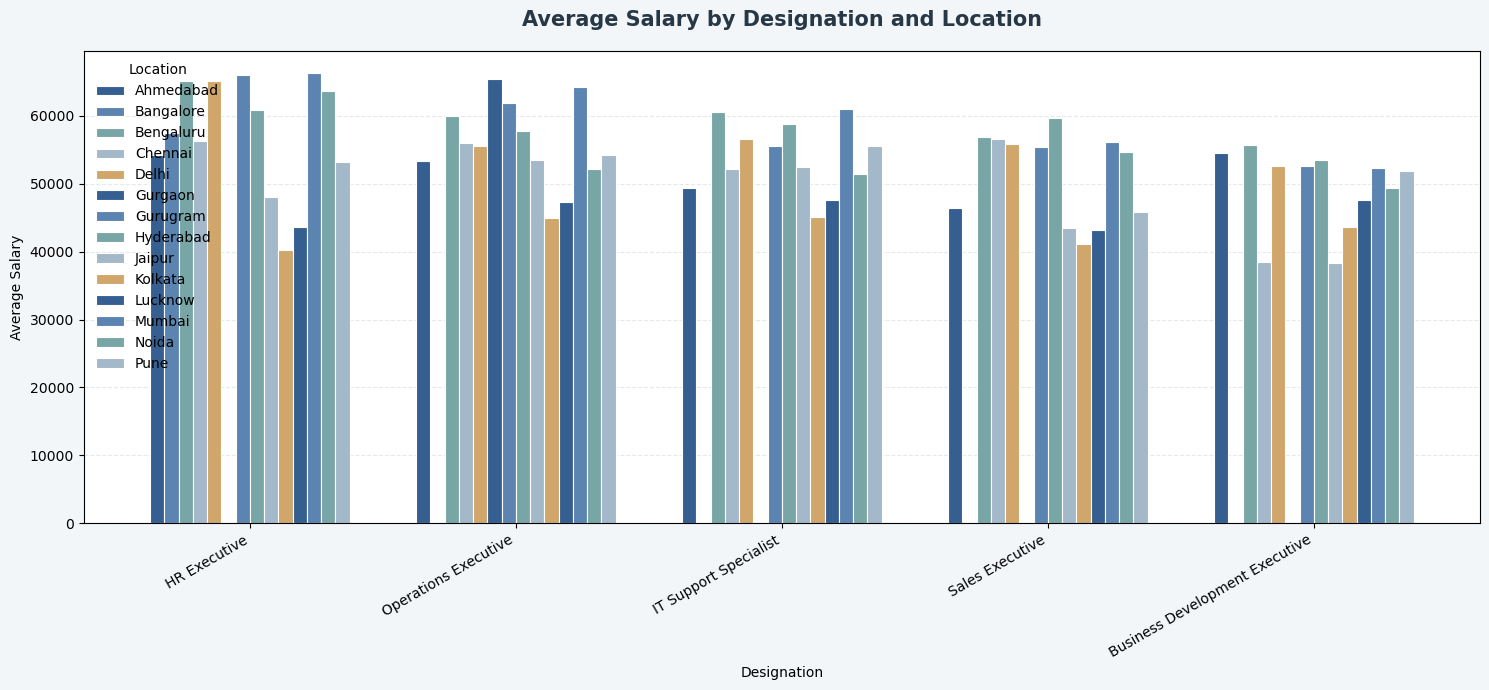

In [58]:
# Calculate average salary by designation and location
data = df.groupby(["Designation", "Location"])["Salary"].mean().unstack()

# Select the next 5 designations after the top 10
next5 = df.groupby("Designation")["Salary"].mean().nlargest(15).index[10:15]

# Professional color palette
colors = ["#365F91", "#5B84B1", "#78A6A6", "#A3B8C8", "#D0A66B"]

# Plot the grouped bar chart
ax = data.loc[next5].plot(
    kind="bar",
    figsize=(15, 7),
    width=0.75,
    color=colors[:len(data.columns)],
    edgecolor="white",
    linewidth=0.8
)
ax.set_facecolor("#FFFFFF")
ax.figure.set_facecolor("#F3F6F9")

plt.title("Average Salary by Designation and Location",
          fontsize=15, fontweight="bold", color="#263746", pad=18)

plt.xlabel("Designation")
plt.ylabel("Average Salary")
plt.xticks(rotation=30, ha="right")

plt.grid(axis="y", linestyle="--", color="#D9E1E8", alpha=0.7)
ax.set_axisbelow(True)

plt.legend(title="Location", frameon=False)
plt.tight_layout()
plt.show()